# ResQ-Stream: Action Stage (Person 3)
**Job:** take the model's *stockout risk scores* and decide **which stock to move from where to where**, before a hospital runs out.

**Pipeline:** telemetry -> risk model (Person 2) -> **optimizer (this notebook)** -> ranked transfer list -> replay to prove it helps.

Uses only packages already on the LinuxONE VM (pandas, numpy, networkx, matplotlib, torch). Run it from inside the `resq-stream` repo folder.

## Cell 1: Setup and proof we are on IBM Z

In [3]:
import os, sys, platform

REPO = "/home/ibm-user/resq-stream"
assert os.path.isdir(REPO + "/model") and os.path.isdir(REPO + "/action"), "model/ or action/ missing in " + REPO

os.chdir(REPO); sys.path.insert(0, REPO)
print("repo root:", os.getcwd())
print("Architecture:", platform.machine(), "| Python", platform.python_version())

repo root: /home/ibm-user/resq-stream
Architecture: s390x | Python 3.12.15


## Cell 2: Load the test simulation and get risk scores
`telemetry_test.csv` is the simulator's recording of 30 days (720 hours) that the model has **never trained on**.
`gnn_probs` returns, for every hour, node and item, the probability of a stockout in the next 6 hours. On the VM it runs the PyTorch model; elsewhere it falls back to the ONNX export.

In [4]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, networkx as nx
from model.config import TEST_CSV, EDGES_CSV, ART_DIR
from model.data import load_csv
from action.predict import gnn_probs
from action.planner import recommend_transfers
from action.replay import replay, compare

test  = load_csv(TEST_CSV)
edges = pd.read_csv(EDGES_CSV)
probs, model_thr, backend = gnn_probs(test)
print(f"risk scores from: {backend} | {len(probs):,} predictions | model's own alert threshold = {model_thr:.2f}")
edges.head()

risk scores from: torch | 28,360 predictions | model's own alert threshold = 0.86


,src,dst,transit_hrs
0,WH-North,DIST-Central,12.0
1,WH-North,DIST-East,12.0
2,WH-South,DIST-Central,12.0
3,WH-South,DIST-East,12.0
4,WH-North,HOSP-01,24.0


## Cell 3: One live decision
Pick the hour with the most at-risk hospital items, show the situation, and ask the planner what to do.

How the planner thinks:
1. **Needs stock** = hospitals whose risk is above the threshold. They get topped up to 24 hours of demand.
2. **Can give** = warehouses, distributors above their reorder point, and *calm* hospitals (they keep 24h for themselves).
3. **Lanes that arrive too late are deleted** (no point shipping if the stockout happens first).
4. **Min-cost flow** (a solver) finds the cheapest set of shipments; riskier hospitals are served first.

In [5]:
RISK = 0.5
hosp_probs = probs.merge(test[["hour","node_id","item","node_type","stock","consumption_rate","event_flag"]],
                         on=["hour","node_id","item"])
hosp_probs = hosp_probs[hosp_probs.node_type == "hospital"]
busiest = hosp_probs[hosp_probs.prob >= RISK].groupby("hour").size().idxmax()
snap = test[test.hour == busiest].merge(probs[probs.hour == busiest][["node_id","item","prob"]], on=["node_id","item"])
print(f"Hour {busiest}: at-risk hospital items:")
display(snap[(snap.node_type=="hospital") & (snap.prob>=RISK)][["node_id","item","stock","consumption_rate","event_flag","prob"]].round(2))
plan_now = recommend_transfers(snap, edges, risk_threshold=RISK)
print("Recommended transfers (most urgent first):")
plan_now

Hour 317: at-risk hospital items:


,node_id,item,stock,consumption_rate,event_flag,prob
8,HOSP-01,epinephrine_1mg,17,4.61,none,0.50
9,HOSP-01,iv_saline_1l,31,5.38,none,0.54
11,HOSP-01,oxygen_cylinder_d,9,2.46,none,0.69
12,HOSP-02,epinephrine_1mg,0,7.05,outbreak_surge,0.97
13,HOSP-02,iv_saline_1l,0,13.69,outbreak_surge,0.96
14,HOSP-02,n95_mask,0,2.78,outbreak_surge,0.97
15,HOSP-02,oxygen_cylinder_d,0,11.95,outbreak_surge,0.97
16,HOSP-03,epinephrine_1mg,15,6.76,none,0.87
17,HOSP-03,iv_saline_1l,9,5.33,none,0.87
18,HOSP-03,n95_mask,20,4.15,none,0.66


Recommended transfers (most urgent first):


,item,from,to,qty,eta_hours,hours_left,margin_hours,risk
0,epinephrine_1mg,HOSP-06,HOSP-01,26,3.0,3.7,0.7,0.502
1,iv_saline_1l,DIST-East,HOSP-04,112,6.0,7.1,1.1,0.887
2,oxygen_cylinder_d,DIST-Central,HOSP-03,53,6.0,9.2,3.2,0.685


## Cell 4: Prove it works (the 'stockouts avoided' metric)
The test recording had **no rerouting**. We replay all 720 hours twice with identical rules:
- **No rerouting** = switch the planner off
- **ResQ-Stream** = at every hour, the planner sees the current stock + the model's risk scores and ships stock

Sanity check: the 'no rerouting' replay should reproduce the stockouts already recorded in the CSV.

In [6]:
import time
base = replay(test, probs, edges, plan=False)
rec_hours = int(test[(test.hour >= base["start_hour"]) & (test.stockout_now == 1)].shape[0])
print(f"sanity check -> replay baseline: {int(base['out'][:, base['is_h']].sum())} stockout-hours | recorded in CSV: {rec_hours}")

t0 = time.time()
act = replay(test, probs, edges, plan=True, risk_threshold=RISK)
print(f"replayed {len(act['out'])} hours in {time.time()-t0:.0f}s | {len(act['plans'])} transfers recommended")
results = compare(base, act)
results

sanity check -> replay baseline: 580 stockout-hours | recorded in CSV: 570
replayed 709 hours in 3s | 316 transfers recommended


,No rerouting,ResQ-Stream,reduction %
stockout episodes,186,39,79.0
stockout hospital-hours,580,151,74.0
unmet demand (units),3083,402,87.0


## Cell 5: Pictures for the demo video

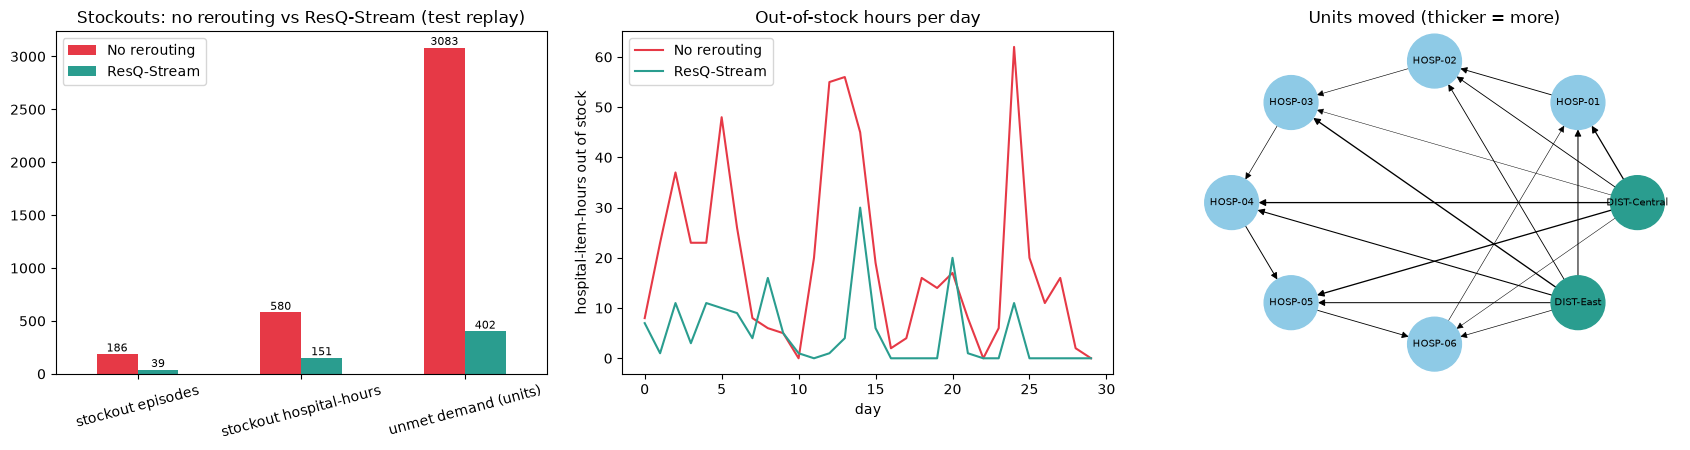

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))

# 1) headline numbers
m = results[["No rerouting", "ResQ-Stream"]]
m.plot.bar(ax=ax[0], rot=15, color=["#e63946", "#2a9d8f"]); ax[0].set_title("Stockouts: no rerouting vs ResQ-Stream (test replay)")
for c in ax[0].containers: ax[0].bar_label(c, fontsize=8)

# 2) stockout hospital-hours per day
b = base["out"][:, base["is_h"]].sum(1); a = act["out"][:, act["is_h"]].sum(1)
days = np.arange(len(b)) // 24
ax[1].plot(pd.Series(b).groupby(days).sum().values, label="No rerouting", color="#e63946")
ax[1].plot(pd.Series(a).groupby(days).sum().values, label="ResQ-Stream", color="#2a9d8f")
ax[1].set_xlabel("day"); ax[1].set_ylabel("hospital-item-hours out of stock"); ax[1].legend(); ax[1].set_title("Out-of-stock hours per day")

# 3) where the stock moved (total units over the replay)
flows = act["plans"].groupby(["from", "to"]).qty.sum().reset_index()
G = nx.DiGraph([(r["from"], r.to, {"qty": int(r.qty)}) for _, r in flows.iterrows()])
col = ["#2a9d8f" if n.startswith("DIST") else ("#e9c46a" if n.startswith("WH") else "#8ecae6") for n in G.nodes]
pos = nx.circular_layout(G)
nx.draw(G, pos, ax=ax[2], with_labels=True, node_color=col, node_size=1500, font_size=7, arrows=True, width=[0.3 + d["qty"]/1500 for *_, d in G.edges(data=True)])
ax[2].set_title("Units moved (thicker = more)")
plt.tight_layout(); plt.show()

## Cell 6: Plan quality and speed
- **Margin** = how many hours before the hospital would have run out that the shipment lands. Always positive, because late lanes are removed.
- **Planning time** = time the optimizer needs per decision. Add your teammate's model-inference time for the full event-to-recommendation latency.

In [8]:
pl = act["plans"]
print("transfers:", len(pl), "| units moved:", int(pl.qty.sum()))
print("margin before stockout (hours): min %.1f | median %.1f" % (pl.margin_hours.min(), pl.margin_hours.median()))
print("share of units from distributors: %.0f%% | from neighbouring hospitals: %.0f%%" % (
      100*pl[pl["from"].str.startswith("DIST")].qty.sum()/pl.qty.sum(), 100*pl[pl["from"].str.startswith("HOSP")].qty.sum()/pl.qty.sum()))
print("optimizer time per decision: median %.1f ms | 95th pct %.1f ms" % (np.median(act["plan_ms"]), np.percentile(act["plan_ms"], 95)))

transfers: 316 | units moved: 9318
margin before stockout (hours): min 0.0 | median 12.2
share of units from distributors: 77% | from neighbouring hospitals: 23%
optimizer time per decision: median 3.9 ms | 95th pct 5.6 ms


## Cell 7: How sensitive is it to the alert threshold?
A lower threshold acts earlier but moves more stock. The model's own threshold (~0.86) was tuned for *prediction*, not for *action*.

In [9]:
rows = []
for thr in [0.86, 0.5, 0.3]:
    a = replay(test, probs, edges, plan=True, risk_threshold=thr); c = compare(base, a)
    rows.append({"threshold": thr, "transfers": len(a["plans"]),
                 "episodes avoided %": c.loc["stockout episodes", "reduction %"],
                 "unmet demand reduced %": c.loc["unmet demand (units)", "reduction %"]})
pd.DataFrame(rows)

,threshold,transfers,episodes avoided %,unmet demand reduced %
0,0.86,266,74.0,83.0
1,0.50,316,79.0,87.0
2,0.30,370,82.0,87.0


## Cell 8: Save outputs for the team and the README

In [10]:
os.makedirs("shared", exist_ok=True)
act["plans"].to_csv("shared/action_transfers_test_replay.csv", index=False)
results.to_csv("shared/action_results.csv")
print("saved shared/action_transfers_test_replay.csv and shared/action_results.csv")

saved shared/action_transfers_test_replay.csv and shared/action_results.csv
